In [1]:
import torch
import os
# Set GPU
os.environ["CUDA_VISIBLE_DEVICES"] = "1"  # Select the GPU index
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

import torch.nn.functional as F
import torch.nn as nn
import torch.optim as optim
from scipy.special import comb
import numpy as np
import math
from opt_einsum import contract
from torch.autograd import Variable
from reed_muller_modules.hadamard import *
import matplotlib.pyplot as plt
from torch.optim.lr_scheduler import _LRScheduler, OneCycleLR
import time
from scipy.io import savemat
import pickle
from reed_muller_modules.reedmuller_codebook import *
from itertools import combinations
from scipy.signal import savgol_filter


Using device: cuda
CUDA version of Hadamard transform isn't installed. Will use Pytorch's version, which is much slower.


# Helper functions

In [2]:
def repetition_code_matrices(device, m=8):
    M_dict = {}
    for i in range(1, m):
        M_dict[i] = torch.ones(1, 2**i).to(device)
    return M_dict

def numpy_to_torch(tensor):
    return torch.from_numpy(tensor).float()

def first_order_encoder_Plotkin(msg_bits, order_of_RM1):
    repetition_M_dict = repetition_code_matrices(device, order_of_RM1)
    u_level0 = msg_bits[:, 0:1]
    v_level0 = msg_bits[:, 1:2]
    
    for i in range(2, order_of_RM1+1):
        u_level0 = torch.cat([u_level0, u_level0 * v_level0], dim=1)
        v_level0 = msg_bits[:, i:i+1].mm(repetition_M_dict[i-1])
    u_levelm = torch.cat([u_level0, u_level0 * v_level0], dim=1)
    
    return u_levelm

def generate_indices(all_msg_bits):
    # Get the number of bits and total number of messages
    num_bits = all_msg_bits.shape[1]
    
    # Initialize the indices tensors
    MinusOneIdx = []
    PlusOneIdx = []
    
    # For each bit position
    for i in range(num_bits):
        # Find indices where the bit is -1 and 1
        minus_one = torch.where(all_msg_bits[:, i] == -1)[0]
        plus_one = torch.where(all_msg_bits[:, i] == 1)[0]
        
        MinusOneIdx.append(minus_one)
        PlusOneIdx.append(plus_one)
    
    # Convert lists to tensors
    MinusOneIdx = torch.stack(MinusOneIdx).to(all_msg_bits.device)
    PlusOneIdx = torch.stack(PlusOneIdx).to(all_msg_bits.device)
    
    return MinusOneIdx, PlusOneIdx

def snr_db2sigma(train_snr):
    return 10**(-train_snr*1.0/20)/math.sqrt(2)

def log_sum_exp1(LLR_vector):
    sum_vector = LLR_vector.sum(dim=1, keepdim=True)
    sum_concat = torch.cat([sum_vector, torch.zeros_like(sum_vector)], dim=1)
    return torch.logsumexp(sum_concat, dim=1) - torch.logsumexp(LLR_vector, dim=1) 

def bin_array(num, m):
    """Convert a positive integer num into an m-bit bit vector"""
    return np.array(list(np.binary_repr(num).zfill(m))).astype(np.float32).reshape(-1)

def RM_mm_SoftMAP_decoder(LLR, RM_mm_codebook_PlusOne, RM_mm_codebook_MinusOne):
    max_PlusOne, _ = torch.max(contract('lk, ijk ->  lij', LLR, RM_mm_codebook_PlusOne), 2)
    max_MinusOne, _ = torch.max(contract('lk, ijk ->  lij', LLR, RM_mm_codebook_MinusOne), 2)
    
    return max_PlusOne - max_MinusOne

def first_order_Mul_matrices(device, m=8):
    Mul_Ind_Zero_dict, Mul_Ind_One_dict = {}, {}
    
    for i in range(1, m):
        # Loading the Mul_matrices
        try:
            Mul_Ind_Zero_dict[i] = Variable(torch.load(f'./data/{i}/Mul_this_matrix_Ind_Zero.pt')).to(device)
            Mul_Ind_One_dict[i] = Variable(torch.load(f'./data/{i}/Mul_this_matrix_Ind_One.pt')).to(device)
        except:
            print(f"Warning: Could not load matrices for m={i}. Please make sure the data files exist.")
    
    return Mul_Ind_Zero_dict, Mul_Ind_One_dict

def first_order_generator_matrices(device, m=8):
    G_dict = {}
    for i in range(1, m):
        RM_Class = ReedMuller(1, i if i>0 else 1)
        Generator_Matrix = numpy_to_torch(RM_Class.Generator_Matrix[:, ::-1].copy())
        G_dict[i] = Generator_Matrix.to(device)
    return G_dict

def power_constraint(codewords, gnet_top, power_constraint_type, training_mode):
    if power_constraint_type == 'hard_power_block':
        return F.normalize(codewords, p=2, dim=1)*np.sqrt(codewords.shape[1])
    else: # 'hard_power_bit'
        return codewords/codewords.abs()

def llr_info_bits(hadamard_transform_llr, order_of_RM1, Mul_Ind_Zero_dict, Mul_Ind_One_dict): 
    max_1, _ = hadamard_transform_llr.max(1, keepdim=True)
    min_1, _ = hadamard_transform_llr.min(1, keepdim=True)
    LLR_zero_column = max_1 + min_1 

    max_zero, _ = torch.max(contract('ij, kj ->  ikj', hadamard_transform_llr.abs(), Mul_Ind_Zero_dict[order_of_RM1]), 2)
    max_one, _ = torch.max(contract('ij, kj ->  ikj', hadamard_transform_llr.abs(), Mul_Ind_One_dict[order_of_RM1]), 2)
    LLR_remaining = max_zero - max_one
    return torch.cat([LLR_zero_column, LLR_remaining], dim=1)

def FirstOrder_SoftFHT_InfoBits_decoder(llr, order_of_RM1, Mul_Ind_Zero_dict, Mul_Ind_One_dict):
    hadamard_transform_llr = hadamard_transform_torch(llr)  # shape (batch_size, 2^m)
    return llr_info_bits(hadamard_transform_llr, order_of_RM1, Mul_Ind_Zero_dict, Mul_Ind_One_dict)

def errors_ber(y_true, y_pred):
    y_true = y_true.view(y_true.shape[0], -1, 1)
    y_pred = y_pred.view(y_pred.shape[0], -1, 1)
    myOtherTensor = torch.ne(torch.round(y_true), torch.round(y_pred)).float()
    res = sum(sum(myOtherTensor))/(myOtherTensor.shape[0]*myOtherTensor.shape[1])
    return res

def errors_bler(y_true, y_pred):
    y_true = y_true.view(y_true.shape[0], -1, 1)
    y_pred = y_pred.view(y_pred.shape[0], -1, 1)
    decoded_bits = torch.round(y_pred).cpu()
    X_test = torch.round(y_true).cpu()
    tp0 = (abs(decoded_bits-X_test)).view([X_test.shape[0],X_test.shape[1]])
    tp0 = tp0.detach().cpu().numpy()
    bler_err_rate = sum(np.sum(tp0,axis=1)>0)*1.0/(X_test.shape[0])
    return bler_err_rate


# Improved Neural network models with dropout

In [3]:
class g_Full(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, dropout_rate=0.1):
        super(g_Full, self).__init__()
        
        self.input_size = input_size
        self.half_input_size = int(input_size/2)
        self.hidden_size = hidden_size
        self.output_size = output_size
        
        self.fc1 = nn.Linear(self.input_size, self.hidden_size, bias=True)
        self.fc2 = nn.Linear(self.hidden_size, self.hidden_size, bias=True)
        self.fc3 = nn.Linear(self.hidden_size, self.hidden_size, bias=True)
        self.fc4 = nn.Linear(self.hidden_size, self.output_size, bias=True)
        
        self.dropout = nn.Dropout(dropout_rate)
        self.skip_scale = nn.Parameter(torch.tensor(0.1))  # Learnable skip connection scaling
        
    def forward(self, y):
        x = F.selu(self.fc1(y))
        x = self.dropout(x)
        x = F.selu(self.fc2(x))
        x = self.dropout(x)
        x = F.selu(self.fc3(x))
        x = self.dropout(x)
        x = self.fc4(x) + self.skip_scale * y[:, :, :self.half_input_size]*y[:,:, self.half_input_size:]
        return x

class f_Full(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, dropout_rate=0.1):
        super(f_Full, self).__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        
        self.fc1 = nn.Linear(self.input_size, self.hidden_size, bias=True)
        self.fc2 = nn.Linear(self.hidden_size, self.hidden_size, bias=True)
        self.fc3 = nn.Linear(self.hidden_size, self.hidden_size, bias=True)
        self.fc4 = nn.Linear(self.hidden_size, self.output_size, bias=True)
        
        self.dropout = nn.Dropout(dropout_rate)

    def forward(self, y):
        x = F.selu(self.fc1(y))
        x = self.dropout(x)
        x = F.selu(self.fc2(x))
        x = self.dropout(x)
        x = F.selu(self.fc3(x))
        x = self.dropout(x)
        x = self.fc4(x)
        return x

# Improved weight initialization
def improved_weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        m.weight.data.normal_(0.0, 0.01)
    elif classname.find('BatchNorm') != -1:
        m.weight.data.normal_(0.0, 0.01)
        m.bias.data.fill_(0)
    elif classname.find('Linear') != -1:
        # Initialize close to zero for better initial behavior
        m.weight.data.normal_(0.0, 0.01)
        m.bias.data.fill_(0)

def rm_encoder_plotkin(msg_bits, r, m):
    if r == 0:
        out = msg_bits.repeat(1, 2**m)
        return out
    elif r == 1:
        # Create a new tensor with the desired arrangement
        rearranged_msg_bits = torch.cat([
            msg_bits[:, 0:1],  # Keep the first element
            msg_bits[:, 1:].flip(1)  # Flip the rest of the elements
        ], dim=1)
        out = first_order_encoder_Plotkin(rearranged_msg_bits.to(device), m)
        return out
    elif r == m:
        k1 = 2**(m-1)
        u = rm_encoder_plotkin(msg_bits[:,:k1], r-1, m-1)
        v = rm_encoder_plotkin(msg_bits[:,k1:], r-1, m-1)
        out = torch.cat([u, (u * v)], dim=1)
        return out
    else:
        k1 = int(sum([comb(m-1, i) for i in range(r+1)]))
        k2 = int(sum([comb(m-1, i) for i in range(r)]))
        u = rm_encoder_plotkin(msg_bits[:,:k1], r, m-1)
        v = rm_encoder_plotkin(msg_bits[:,k1:], r-1, m-1)
        out = torch.cat([u, (u * v)], dim=1)
        return out

def rm_encoder_plotkin_neural(msg_bits, r, m, gnet_dict, power_constraint_type='hard_power_block', training_mode='train'):
    """
    Reed-Muller encoder with neural network and power constraint only at final output.
    
    Args:
        msg_bits: Input message bits
        r: RM code parameter r
        m: RM code parameter m
        gnet_dict: Dictionary of neural networks
        power_constraint_type: Type of power constraint to apply
        training_mode: 'train' or 'test'
    """
    def encode_without_constraint(msg_bits, r, m):
        if r == 0:
            return msg_bits.repeat(1, 2**m)
        elif r == 1:
            # Create a new tensor with the desired arrangement
            rearranged_msg_bits = torch.cat([
                msg_bits[:, 0:1],  # Keep the first element
                msg_bits[:, 1:].flip(1)  # Flip the rest of the elements
            ], dim=1)
            return first_order_encoder_Plotkin(rearranged_msg_bits.to(device), m)
        elif r == m:
            k1 = 2**(m-1)
            u = encode_without_constraint(msg_bits[:,:k1], r-1, m-1)
            v = encode_without_constraint(msg_bits[:,k1:], r-1, m-1)
            return torch.cat([u, (u * v)], dim=1)
        else:
            k1 = int(sum([comb(m-1, i) for i in range(r+1)]))
            k2 = int(sum([comb(m-1, i) for i in range(r)]))
            u = encode_without_constraint(msg_bits[:,:k1], r, m-1)
            v = encode_without_constraint(msg_bits[:,k1:], r-1, m-1)
            
            # Apply neural network transform but don't constrain yet
            if m in gnet_dict:
                out = torch.cat([u, gnet_dict[m](torch.cat([u.unsqueeze(2), v.unsqueeze(2)], dim=2)).squeeze(2)], dim=1)
            else:
                # Fallback to standard Plotkin construction if no neural network is available for this level
                out = torch.cat([u, u * v], dim=1)
            
            return out
    
    # First encode without power constraint
    encoded = encode_without_constraint(msg_bits, r, m)
    
    # Apply power constraint only at the final output
    return power_constraint(encoded, None, power_constraint_type, training_mode)

def rm_decoder_dumer_neural(llr, r, m, fnet_dict, gnet_dict, Mul_Ind_Zero_dict, Mul_Ind_One_dict, m1=None):
    """
    Neural decoder for Reed-Muller codes.
    
    Args:
        llr: Log-likelihood ratios
        r: RM code parameter r
        m: RM code parameter m
        fnet_dict: Dictionary of neural decoder networks
        gnet_dict: Dictionary of neural encoder networks (needed for MAP decoding)
        Mul_Ind_Zero_dict, Mul_Ind_One_dict: Matrices for first-order decoding
        m1: Original m value for proper indexing in recursive calls
    """
    if m1 is None:
        m1 = m
        
    n = 2**m
    if r == 0:
        decoded_message = torch.tanh((torch.sum(llr, dim=1))/2).unsqueeze(1)
        return decoded_message
    elif r == 1:
        decoded_message = torch.tanh(FirstOrder_SoftFHT_InfoBits_decoder(llr, m, Mul_Ind_Zero_dict, Mul_Ind_One_dict)/2)
        return decoded_message
    elif r == m:
        k = sum(math.comb(m, i) for i in range(r+1))
        all_msg_bits_mm_leaf = []
        msg_length = k
        
        for i in range(2**k-1, -1, -1):
            bits = bin_array(i, msg_length)
            all_msg_bits_mm_leaf.append(bits*2-1)
            
        all_msg_bits_mm_leaf = torch.tensor(np.array(all_msg_bits_mm_leaf)).to(device)
        MinusOneIdx_mm_leaf, PlusOneIdx_mm_leaf = generate_indices(all_msg_bits_mm_leaf)
        
        with torch.no_grad():
            RM_mm_codebook = rm_encoder_plotkin_neural(all_msg_bits_mm_leaf, r, m, gnet_dict)
        
        RM_mm_codebook_PlusOne = RM_mm_codebook[PlusOneIdx_mm_leaf]
        RM_mm_codebook_MinusOne = RM_mm_codebook[MinusOneIdx_mm_leaf]
        
        decoded_message = torch.tanh(RM_mm_SoftMAP_decoder(llr, RM_mm_codebook_PlusOne, RM_mm_codebook_MinusOne)/2)
        return decoded_message
    else:
        # Split LLR into two halves
        llr_left = llr[:, :n//2]
        llr_right = llr[:, n//2:]

        # Use consistent indexing for decoder networks
        level = m1 - m + 1
        
        # Decode left child (v) only if we have the corresponding neural network
        if 2*level - 1 in fnet_dict:
            llr_v = fnet_dict[2*level - 1](torch.cat([llr_left.unsqueeze(2), llr_right.unsqueeze(2)], dim=2)).squeeze(2) + \
                  log_sum_exp1(torch.cat([llr_left.unsqueeze(2), llr_right.unsqueeze(2)], dim=2).permute(0, 2, 1))
        else:
            # Fallback to regular log-sum-exp operation
            llr_v = log_sum_exp1(torch.cat([llr_left.unsqueeze(2), llr_right.unsqueeze(2)], dim=2).permute(0, 2, 1))
            
        v_hat = rm_decoder_dumer_neural(llr_v, r-1, m-1, fnet_dict, gnet_dict, Mul_Ind_Zero_dict, Mul_Ind_One_dict, m1)
        v_c = rm_encoder_plotkin(v_hat.sign(), r-1, m-1)
        
        # Compute LLR for right child (u)
        if 2*level in fnet_dict:
            llr_u = fnet_dict[2*level](torch.cat([llr_left.unsqueeze(2), llr_right.unsqueeze(2), 
                                                 llr_v.unsqueeze(2), v_c.unsqueeze(2)], dim=2)).squeeze(2) + \
                  llr_left + v_c * llr_right
        else:
            # Fallback to standard operation
            llr_u = llr_left + v_c * llr_right
            
        u_hat = rm_decoder_dumer_neural(llr_u, r, m-1, fnet_dict, gnet_dict, Mul_Ind_Zero_dict, Mul_Ind_One_dict, m1)
        
        # Combine decoded bits
        decoded_message = torch.cat([u_hat, v_hat], dim=1)
        return decoded_message


In [4]:
def awgn_channel(codewords, snr):
    noise_sigma = snr_db2sigma(snr)
    standard_Gaussian = torch.randn_like(codewords)
    corrupted_codewords = codewords + noise_sigma * standard_Gaussian
    llrs = (2/(noise_sigma**2)) * corrupted_codewords
    return llrs

def save_model_state(gnet_dict, fnet_dict, path, prefix="", m_max=8):
    """Save encoder and decoder model states with verification."""
    # Ensure directory exists
    os.makedirs(os.path.join(path, 'Models'), exist_ok=True)
    
    # Save encoder state
    encoder_state = {}
    for i in range(3, m_max+1):
        if i in gnet_dict:
            encoder_state[f'g{i}'] = gnet_dict[i].state_dict()
            
    # Save decoder state
    decoder_state = {}
    for i in range(1, 2*m_max-3):
        if i in fnet_dict:
            decoder_state[f'f{i}'] = fnet_dict[i].state_dict()
    
    # Save states with verification
    encoder_path = f'{path}/Models/{prefix}Encoder_NN.pt'
    decoder_path = f'{path}/Models/{prefix}Decoder_NN.pt'
    
    torch.save(encoder_state, encoder_path)
    torch.save(decoder_state, decoder_path)
    
    # Verify saved files
    try:
        torch.load(encoder_path)
        torch.load(decoder_path)
        print(f"Successfully saved and verified models with prefix '{prefix}'")
    except Exception as e:
        print(f"Error verifying saved models: {e}")
        
    return encoder_state, decoder_state

def load_model_state(gnet_dict, fnet_dict, path, prefix="", m_max=8):
    """Load encoder and decoder model states with verification."""
    # Load saved states
    try:
        encoder_state = torch.load(f'{path}/Models/{prefix}Encoder_NN.pt')
        decoder_state = torch.load(f'{path}/Models/{prefix}Decoder_NN.pt')
    except FileNotFoundError as e:
        print(f"Error loading model files: {e}")
        return gnet_dict, fnet_dict
    
    # Load encoder weights with verification
    for i in range(3, m_max+1):
        if i in gnet_dict and f'g{i}' in encoder_state:
            try:
                gnet_dict[i].load_state_dict(encoder_state[f'g{i}'])
                gnet_dict[i].eval()
                print(f"Successfully loaded encoder g{i}")
            except Exception as e:
                print(f"Error loading encoder g{i}: {e}")
    
    # Load decoder weights with verification
    for i in range(1, 2*m_max-3):
        if i in fnet_dict and f'f{i}' in decoder_state:
            try:
                fnet_dict[i].load_state_dict(decoder_state[f'f{i}'])
                fnet_dict[i].eval()
                print(f"Successfully loaded decoder f{i}")
            except Exception as e:
                print(f"Error loading decoder f{i}: {e}")
    
    return gnet_dict, fnet_dict

def validate_submodule_transfer(small_model_dict, large_model_dict, r_small, m_small, r_large, m_large, test_batch_size=10):
    """Validates that submodules were correctly transferred by comparing outputs on test data."""
    print("Validating submodule transfer...")
    
    # Compute code dimensions
    k_small = sum(math.comb(m_small, i) for i in range(r_small+1))
    k_large = sum(math.comb(m_large, i) for i in range(r_large+1))
    
    # Generate test message
    with torch.no_grad():
        test_msg = 2*torch.randint(0, 2, (test_batch_size, k_small), dtype=torch.float32).to(device)-1
        
        # Get output from small model
        small_output = rm_encoder_plotkin_neural(test_msg, r_small, m_small, small_model_dict)
        
        # Create appropriate input for large model
        test_msg_large = torch.zeros(test_batch_size, k_large).to(device)
        # Place the small test message in the right location
        # This depends on the specific hierarchical structure
        # For this example, we'll assume small module maps to a specific section
        test_msg_large[:, :k_small] = test_msg
        
        # Get output from large model
        large_output = rm_encoder_plotkin_neural(test_msg_large, r_large, m_large, large_model_dict)
        
        # Compare outputs - specific comparison depends on where in the hierarchy the
        # small model should map to in the large model
        # For simplicity, we'll compare a section of the output
        error = torch.norm(small_output - large_output[:, :small_output.shape[1]])
        
        print(f"Submodule transfer validation error: {error.item()}")
        if error.item() > 1.0:
            print("WARNING: Large error in submodule transfer validation!")
            print("The pretrained weights may not be correctly applied.")
        else:
            print("Submodule transfer validation successful!")
            
        return error.item()

In [5]:



def train_ko_code(r, m, gnet_dict, fnet_dict, 
                  Mul_Ind_Zero_dict, Mul_Ind_One_dict,
                  batch_size=10000, small_batch_size=1000, 
                  hidden_size=64, num_epochs=300,
                  enc_train_iters=10, dec_train_iters=50,
                  enc_train_snr=1.0, dec_train_snr=0.0,
                  save_dir=None, freeze_submodules=False,
                  pretrained_levels=None, progressive_unfreeze=True):
    """
    Train a KO code with given parameters and progressive unfreezing
    
    Args:
        r, m: KO code parameters KO(m,r)
        gnet_dict, fnet_dict: Neural network dictionaries
        Mul_Ind_Zero_dict, Mul_Ind_One_dict: Matrices for first-order decoding
        batch_size, small_batch_size: Batch sizes for training
        hidden_size: Size of hidden layers in neural networks
        num_epochs: Number of training epochs
        enc_train_iters, dec_train_iters: Training iterations for encoder and decoder
        enc_train_snr, dec_train_snr: SNR values for encoder and decoder training
        save_dir: Directory to save models
        freeze_submodules: Whether to freeze pretrained submodules
        pretrained_levels: List of levels that use pretrained weights
        progressive_unfreeze: Whether to progressively unfreeze modules during training
        
    Returns:
        losses, bers: Training history
    """
    if save_dir is None:
        save_dir = f"./Results/KO({m},{r})"
    
    os.makedirs(save_dir, exist_ok=True)
    os.makedirs(os.path.join(save_dir, 'Models'), exist_ok=True)
    
    # Compute code dimension
    code_dim_k = sum(math.comb(m, i) for i in range(r+1))
    N = 2**m
    
    print(f"Training KO({m},{r}) code with dimension k={code_dim_k}, block length n={N}")
    print(f"Using batch_size={batch_size}, small_batch_size={small_batch_size}")
    print(f"Encoder SNR={enc_train_snr} dB, Decoder SNR={dec_train_snr} dB")
    
    # Unfreezing schedule for progressive unfreezing
    if progressive_unfreeze and freeze_submodules and pretrained_levels:
        unfreeze_epochs = []
        # Create unfreezing schedule
        for i, level in enumerate(pretrained_levels):
            unfreeze_epoch = int((i+1) * num_epochs / (len(pretrained_levels) + 1))
            unfreeze_epochs.append((unfreeze_epoch, level))
        print(f"Progressive unfreezing schedule: {unfreeze_epochs}")
    
    # Create encoder optimizer
    enc_params = []
    for i in range(3, m+1):
        if i in gnet_dict:
            # If we're freezing certain levels and this is a pretrained level
            if freeze_submodules and pretrained_levels and i in pretrained_levels:
                # Freeze the parameters by not adding them to the optimizer
                for param in gnet_dict[i].parameters():
                    param.requires_grad = False
                print(f"Freezing encoder g{i}")
            else:
                for param in gnet_dict[i].parameters():
                    param.requires_grad = True
                enc_params += list(gnet_dict[i].parameters())
                
    # Create decoder optimizer
    dec_params = []
    for i in range(1, 2*m-3):
        if i in fnet_dict:
            # If we're freezing certain levels and this level corresponds to a pretrained level
            level = (i + 1) // 2  # Convert decoder index to encoder level
            m_level = m - level + 1  # Convert level to m value
            
            if freeze_submodules and pretrained_levels and m_level in pretrained_levels:
                # Freeze the parameters
                for param in fnet_dict[i].parameters():
                    param.requires_grad = False
                print(f"Freezing decoder f{i} (corresponds to level m={m_level})")
            else:
                for param in fnet_dict[i].parameters():
                    param.requires_grad = True
                dec_params += list(fnet_dict[i].parameters())
    
    # Create optimizers with appropriate learning rates
    enc_optimizer = optim.Adam(enc_params, lr=2e-4, betas=(0.9, 0.98), eps=1e-9)
    dec_optimizer = optim.Adam(dec_params, lr=2e-4, betas=(0.9, 0.98), eps=1e-9)
    
    # Create improved schedulers - OneCycleLR instead of WarmupCosineAnnealing
    enc_scheduler = OneCycleLR(
        enc_optimizer,
        max_lr=2e-4,
        total_steps=num_epochs * enc_train_iters,
        pct_start=0.3,  # 30% of training is warmup
        div_factor=25.0,  # initial_lr = max_lr/25
        final_div_factor=1000.0  # min_lr = initial_lr/10000
    )
    
    dec_scheduler = OneCycleLR(
        dec_optimizer,
        max_lr=2e-4,
        total_steps=num_epochs * dec_train_iters,
        pct_start=0.3,
        div_factor=25.0,
        final_div_factor=1000.0
    )
    
    # Loss function
    criterion = nn.BCEWithLogitsLoss()
    
    # Training history
    losses = []
    bers = []
    best_loss = float('inf')
    patience = 20  # Early stopping patience
    patience_counter = 0
    
    # Save initial model
    save_model_state(gnet_dict, fnet_dict, save_dir, prefix="initial_", m_max=m)
    
    # Initialize gradual unfreezing tracker
    unfrozen_levels = set()
    
    # Create validation set for monitoring progress
    val_msg_bits = 2*torch.randint(0, 2, (1000, code_dim_k), dtype=torch.float32).to(device)-1
    
    try:
        for epoch in range(num_epochs):
            start_time = time.time()
            
            # Check if we need to unfreeze any levels according to schedule
            if progressive_unfreeze and freeze_submodules and pretrained_levels:
                for unfreeze_epoch, level in unfreeze_epochs:
                    if epoch == unfreeze_epoch and level not in unfrozen_levels:
                        print(f"Unfreezing level m={level} (epoch {epoch})")
                        
                        # Unfreeze encoder
                        if level in gnet_dict:
                            for param in gnet_dict[level].parameters():
                                param.requires_grad = True
                            enc_params.extend(list(gnet_dict[level].parameters()))
                        
                        # Unfreeze corresponding decoders
                        for i in range(1, 2*m-3):
                            decoder_level = (i + 1) // 2
                            m_decoder_level = m - decoder_level + 1
                            if m_decoder_level == level and i in fnet_dict:
                                for param in fnet_dict[i].parameters():
                                    param.requires_grad = True
                                dec_params.extend(list(fnet_dict[i].parameters()))
                        
                        # Recreate optimizers with updated parameter lists
                        enc_optimizer = optim.Adam(enc_params, lr=1e-4, betas=(0.9, 0.98), eps=1e-9)
                        dec_optimizer = optim.Adam(dec_params, lr=1e-4, betas=(0.9, 0.98), eps=1e-9)
                        
                        # Create new schedulers
                        remaining_epochs = num_epochs - epoch
                        enc_scheduler = OneCycleLR(
                            enc_optimizer,
                            max_lr=1e-4,  # Lower max learning rate for fine tuning
                            total_steps=remaining_epochs * enc_train_iters,
                            pct_start=0.2,  # 20% of remaining training for warmup
                            div_factor=25.0,
                            final_div_factor=10000.0
                        )
                        
                        dec_scheduler = OneCycleLR(
                            dec_optimizer,
                            max_lr=1e-4,
                            total_steps=remaining_epochs * dec_train_iters,
                            pct_start=0.2,
                            div_factor=25.0,
                            final_div_factor=10000.0
                        )
                        
                        # Add to unfrozen levels
                        unfrozen_levels.add(level)
            
            # Generate batch of message bits
            msg_bits_large_batch = 2*torch.randint(0, 2, (batch_size, code_dim_k), 
                                                  dtype=torch.float32).to(device)-1
            
            num_small_batches = batch_size // small_batch_size
            epoch_loss = 0
            epoch_ber = 0
            
            # Train decoder
            for _ in range(dec_train_iters):
                dec_optimizer.zero_grad()
                decoder_loss = 0
                
                for i in range(num_small_batches):
                    # Get mini-batch
                    start, end = i*small_batch_size, (i+1)*small_batch_size
                    msg_bits = msg_bits_large_batch[start:end]
                    
                    # Forward pass through encoder
                    transmit_codewords = rm_encoder_plotkin_neural(msg_bits, r, m, gnet_dict)
                    
                    # Add noise
                    corrupted_codewords = awgn_channel(transmit_codewords, dec_train_snr)
                    
                    # Decode
                    decoded_message = rm_decoder_dumer_neural(corrupted_codewords, r, m, fnet_dict, gnet_dict, 
                                                            Mul_Ind_Zero_dict, Mul_Ind_One_dict)
                    
                    # Calculate loss
                    loss = criterion(0.5*decoded_message+0.5, 0.5*msg_bits+0.5) / num_small_batches
                    decoder_loss += loss.item()
                    
                    # Backward pass
                    loss.backward()
                
                # Clip gradients to prevent explosion
                torch.nn.utils.clip_grad_norm_(dec_params, 1.0)
                
                # Update decoder weights
                dec_optimizer.step()
                dec_scheduler.step()
            
            # Train encoder
            for _ in range(enc_train_iters):
                enc_optimizer.zero_grad()
                encoder_loss = 0
                
                for i in range(num_small_batches):
                    # Get mini-batch
                    start, end = i*small_batch_size, (i+1)*small_batch_size
                    msg_bits = msg_bits_large_batch[start:end]
                    
                    # Forward pass through encoder
                    transmit_codewords = rm_encoder_plotkin_neural(msg_bits, r, m, gnet_dict)
                    
                    # Add noise
                    corrupted_codewords = awgn_channel(transmit_codewords, enc_train_snr)
                    
                    # Decode
                    decoded_message = rm_decoder_dumer_neural(corrupted_codewords, r, m, fnet_dict, gnet_dict, 
                                                            Mul_Ind_Zero_dict, Mul_Ind_One_dict)
                    
                    # Calculate loss
                    loss = criterion(0.5*decoded_message+0.5, 0.5*msg_bits+0.5) / num_small_batches
                    encoder_loss += loss.item()
                    
                    # Calculate BER
                    ber = errors_ber(msg_bits, decoded_message.sign())
                    epoch_ber = ber.item()
                    
                    # Backward pass
                    loss.backward()
                    
                # Clip gradients
                torch.nn.utils.clip_grad_norm_(enc_params, 1.0)
                
                # Update encoder weights
                enc_optimizer.step()
                enc_scheduler.step()
                epoch_loss = encoder_loss
            
            # Evaluate on validation set
            with torch.no_grad():
                val_codewords = rm_encoder_plotkin_neural(val_msg_bits, r, m, gnet_dict)
                val_corrupted = awgn_channel(val_codewords, enc_train_snr)
                val_decoded = rm_decoder_dumer_neural(val_corrupted, r, m, fnet_dict, gnet_dict, 
                                                    Mul_Ind_Zero_dict, Mul_Ind_One_dict)
                val_loss = criterion(0.5*val_decoded+0.5, 0.5*val_msg_bits+0.5).item()
                val_ber = errors_ber(val_msg_bits, val_decoded.sign()).item()
            
            # Store results
            losses.append(val_loss)
            bers.append(val_ber)
            
            # Print progress with more detailed information
            print(f'[{epoch+1}/{num_epochs}] Train Loss: {epoch_loss:.6f} Val Loss: {val_loss:.6f} Val BER: {val_ber:.6f}')
            print(f"Time for one epoch: {(time.time() - start_time)/60:.4f} minutes")
            print(f"Encoder LR: {enc_optimizer.param_groups[0]['lr']:.6f}, Decoder LR: {dec_optimizer.param_groups[0]['lr']:.6f}")
            
            # Check for early stopping
            if val_loss < best_loss:
                best_loss = val_loss
                patience_counter = 0
                # Save best model
                save_model_state(gnet_dict, fnet_dict, save_dir, prefix=f"best_", m_max=m)
            else:
                patience_counter += 1
                
            # Save model at regular intervals
            if (epoch + 1) % 10 == 0 or epoch == 0:
                save_model_state(gnet_dict, fnet_dict, save_dir, prefix=f"epoch_{epoch+1}_", m_max=m)
            
#             # Early stopping
#             if patience_counter >= patience:
#                 print(f"Early stopping at epoch {epoch+1} as validation loss has not improved for {patience} epochs")
#                 break
                
    except KeyboardInterrupt:
        print("Training interrupted!")
        
    # Save final model
    save_model_state(gnet_dict, fnet_dict, save_dir, prefix="final_", m_max=m)
    
    # Plot training curves
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(losses)
    plt.title('Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.grid(True)
    
    plt.subplot(1, 2, 2)
    plt.plot(bers)
    plt.title('Validation BER')
    plt.xlabel('Epoch')
    plt.ylabel('BER')
    plt.grid(True)
    
    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, 'training_curves.png'))
    
    # Save training history
    np.savez(os.path.join(save_dir, 'training_history.npz'), 
             losses=np.array(losses), 
             bers=np.array(bers))
    
    return losses, bers

#

In [6]:
def hierarchical_training():
    """
    Implements hierarchical training for KO(9,4):
    1. Check if KO(4,3) and KO(4,2) pretrained weights exist
    2. If they don't exist, train them
    3. Train KO(9,4) using pretrained weights from KO(4,3) and KO(4,2)
    """
    print("Starting hierarchical KO code training for KO(9,4)...")
    
    # Common parameters
    hidden_size = 120
    dropout_rate = 0.1
    
    # encoder and decoder training snr for KO(4,3) and KO(4,2)
    es1, ds1 = 2, 1
    es2, ds2 = 2, 1
    # Load matrices for decoding
    print("Loading matrices for decoding...")
    Mul_Ind_Zero_dict, Mul_Ind_One_dict = first_order_Mul_matrices(device, 10)  # Up to m=9 (so 10 total)
    
    # Define submodule paths
    save_dir_small1 = f"./Results/KO(4,3)_improved_{es1, ds1}"
    save_dir_small2 = f"./Results/KO(4,2)_improved_{es2, ds2}"
    
    # Check if submodule weights already exist
    submodule1_exists = os.path.exists(f'{save_dir_small1}/Models/final_Encoder_NN.pt')
    submodule2_exists = os.path.exists(f'{save_dir_small2}/Models/final_Encoder_NN.pt')
    
    r_small1, m_small1 = 3, 4
    r_small2, m_small2 = 2, 4
    
    # Initialize submodule dictionaries
    gnet_dict_small1 = {}
    fnet_dict_small1 = {}
    gnet_dict_small2 = {}
    fnet_dict_small2 = {}
    
    #################################################
    # Step 1: Check/Train KO(4,3)
    #################################################
    if not submodule1_exists:
        k_small1 = sum(math.comb(m_small1, i) for i in range(r_small1+1))
        print(f"\n\n======= Starting KO({m_small1},{r_small1}) training =======")
        print(f"Code parameters: k={k_small1}, n={2**m_small1}")
        
        # Initialize networks
        for i in range(3, m_small1+1):
            gnet_dict_small1[i] = g_Full(2, hidden_size, 1, dropout_rate).to(device)
            gnet_dict_small1[i].apply(improved_weights_init)
            
        for i in range(1, 2*m_small1-3):
            fnet_dict_small1[i] = f_Full(2 if i % 2 == 1 else 4, hidden_size, 1, dropout_rate).to(device)
            fnet_dict_small1[i].apply(improved_weights_init)
        
        # Train
        train_ko_code(
            r=r_small1, 
            m=m_small1, 
            gnet_dict=gnet_dict_small1, 
            fnet_dict=fnet_dict_small1,
            Mul_Ind_Zero_dict=Mul_Ind_Zero_dict, 
            Mul_Ind_One_dict=Mul_Ind_One_dict,
            batch_size=4000,
            small_batch_size=1000,
            hidden_size=hidden_size,
            num_epochs=200,
            enc_train_iters=20,
            dec_train_iters=200,
            enc_train_snr=es1,
            dec_train_snr=ds1,
            save_dir=save_dir_small1
        )
        print(f"KO({m_small1},{r_small1}) training completed!")
    else:
        print(f"KO({m_small1},{r_small1}) pretrained weights already exist. Skipping training.")
    
    #################################################
    # Step 2: Check/Train KO(4,2)
    #################################################
    if not submodule2_exists:
        k_small2 = sum(math.comb(m_small2, i) for i in range(r_small2+1))
        print(f"\n\n======= Starting KO({m_small2},{r_small2}) training =======")
        print(f"Code parameters: k={k_small2}, n={2**m_small2}")
        
        # Initialize networks
        for i in range(3, m_small2+1):
            gnet_dict_small2[i] = g_Full(2, hidden_size, 1, dropout_rate).to(device)
            gnet_dict_small2[i].apply(improved_weights_init)
            
        for i in range(1, 2*m_small2-3):
            fnet_dict_small2[i] = f_Full(2 if i % 2 == 1 else 4, hidden_size, 1, dropout_rate).to(device)
            fnet_dict_small2[i].apply(improved_weights_init)
        
        # Train
        train_ko_code(
            r=r_small2, 
            m=m_small2, 
            gnet_dict=gnet_dict_small2, 
            fnet_dict=fnet_dict_small2,
            Mul_Ind_Zero_dict=Mul_Ind_Zero_dict, 
            Mul_Ind_One_dict=Mul_Ind_One_dict,
            batch_size=4000, 
            small_batch_size=1000,
            hidden_size=hidden_size,
            num_epochs=200,
            enc_train_iters=20,
            dec_train_iters=200,
            enc_train_snr=es2,
            dec_train_snr=ds2,
            save_dir=save_dir_small2
        )
        print(f"KO({m_small2},{r_small2}) training completed!")
    else:
        print(f"KO({m_small2},{r_small2}) pretrained weights already exist. Skipping training.")
    
    #################################################
    # Step 3: Train KO(9,4) with improved hierarchical approach
    #################################################
    r_large, m_large = 4, 9
    k_large = sum(math.comb(m_large, i) for i in range(r_large+1))
    print(f"\n\n======= Starting KO({m_large},{r_large}) hierarchical training =======")
    print(f"Code parameters: k={k_large}, n={2**m_large}")
    
    # Create model dictionaries for the large code
    gnet_dict_large = {}
    fnet_dict_large = {}
    
    # Initialize all networks with improved initializations
    for i in range(3, m_large+1):
        gnet_dict_large[i] = g_Full(2, hidden_size, 1, dropout_rate).to(device)
        gnet_dict_large[i].apply(improved_weights_init)
        
    for i in range(1, 2*m_large-3):
        fnet_dict_large[i] = f_Full(2 if i % 2 == 1 else 4, hidden_size, 1, dropout_rate).to(device)
        fnet_dict_large[i].apply(improved_weights_init)
    
    # Load pretrained weights for submodules
    
    # First, load all available weights from KO(4,3)
    encoder_state_small1 = torch.load(f'{save_dir_small1}/Models/best_Encoder_NN.pt')
    decoder_state_small1 = torch.load(f'{save_dir_small1}/Models/best_Decoder_NN.pt')
    
    # Then, load all available weights from KO(4,2)
    encoder_state_small2 = torch.load(f'{save_dir_small2}/Models/best_Encoder_NN.pt')
    decoder_state_small2 = torch.load(f'{save_dir_small2}/Models/best_Decoder_NN.pt')
    
    # Transfer weights from KO(4,3) to the appropriate submodules of KO(9,4)
    # For KO(9,4), we would use KO(4,3) weights at level m=5
    if 'g4' in encoder_state_small1:
        gnet_dict_large[5].load_state_dict(encoder_state_small1['g4'])
        print("Loaded KO(4,3) encoder g4 weights into g5")
    
    # At level m=6 of KO(9,4), we need the KO(4,2) encoder
    if 'g4' in encoder_state_small2:
        gnet_dict_large[6].load_state_dict(encoder_state_small2['g4'])
        print("Loaded KO(4,2) encoder g4 weights into g6")
        
    # Similarly for the decoders - these mappings need to be adjusted for m=9 and r=4
    for i, j in zip([9, 10], [1, 2]):  # Map KO(4,3) decoder indices to KO(9,4)
        key = f'f{j}'
        if key in decoder_state_small1:
            fnet_dict_large[i].load_state_dict(decoder_state_small1[key])
            print(f"Loaded KO(4,3) decoder {key} weights into f{i}")
            
    for i, j in zip([7, 8], [1, 2]):  # Map KO(4,2) decoder indices to KO(9,4)
        key = f'f{j}'
        if key in decoder_state_small2:
            fnet_dict_large[i].load_state_dict(decoder_state_small2[key])
            print(f"Loaded KO(4,2) decoder {key} weights into f{i}")
    
    # Create save directory for the large code
    save_dir_large = f"./Results/KO({m_large},{r_large})_hierarchical_improved3"
    
    # Train hierarchically with improved approach - single stage with progressive unfreezing
    train_ko_code(
        r=r_large, 
        m=m_large, 
        gnet_dict=gnet_dict_large, 
        fnet_dict=fnet_dict_large,
        Mul_Ind_Zero_dict=Mul_Ind_Zero_dict, 
        Mul_Ind_One_dict=Mul_Ind_One_dict,
        batch_size=2000,  
        small_batch_size=500,
        hidden_size=hidden_size,
        num_epochs=300,  
        enc_train_iters=20,
        dec_train_iters=100,
        enc_train_snr=2.0,  # Increased SNR for higher rate code
        dec_train_snr=1.0,  # Increased SNR for higher rate code
        save_dir=save_dir_large,
        freeze_submodules=True,
        pretrained_levels=[5, 6],  # These levels use pretrained weights
        progressive_unfreeze=True  # Progressively unfreeze during training
    )
    
    print("Hierarchical training for KO(9,4) complete!")



Starting hierarchical KO code training for KO(9,4)...
Loading matrices for decoding...


======= Starting KO(4,3) training =======
Code parameters: k=15, n=16
Training KO(4,3) code with dimension k=15, block length n=16
Using batch_size=4000, small_batch_size=1000
Encoder SNR=2 dB, Decoder SNR=1 dB
Successfully saved and verified models with prefix 'initial_'
[1/200] Train Loss: 0.618899 Val Loss: 0.616413 Val BER: 0.233467
Time for one epoch: 0.5079 minutes
Encoder LR: 0.000008, Decoder LR: 0.000008
Successfully saved and verified models with prefix 'best_'
Successfully saved and verified models with prefix 'epoch_1_'
[2/200] Train Loss: 0.618321 Val Loss: 0.619929 Val BER: 0.240600
Time for one epoch: 0.5173 minutes
Encoder LR: 0.000009, Decoder LR: 0.000009
[3/200] Train Loss: 0.617037 Val Loss: 0.618426 Val BER: 0.237733
Time for one epoch: 0.4999 minutes
Encoder LR: 0.000009, Decoder LR: 0.000009
[4/200] Train Loss: 0.618582 Val Loss: 0.617663 Val BER: 0.235067
Time for one epoch:

[46/200] Train Loss: 0.563980 Val Loss: 0.564109 Val BER: 0.117000
Time for one epoch: 0.4731 minutes
Encoder LR: 0.000175, Decoder LR: 0.000175
Successfully saved and verified models with prefix 'best_'
[47/200] Train Loss: 0.553028 Val Loss: 0.551293 Val BER: 0.096000
Time for one epoch: 0.4698 minutes
Encoder LR: 0.000179, Decoder LR: 0.000179
Successfully saved and verified models with prefix 'best_'
[48/200] Train Loss: 0.552512 Val Loss: 0.550699 Val BER: 0.094400
Time for one epoch: 0.4682 minutes
Encoder LR: 0.000182, Decoder LR: 0.000182
Successfully saved and verified models with prefix 'best_'
[49/200] Train Loss: 0.551802 Val Loss: 0.548299 Val BER: 0.090600
Time for one epoch: 0.4719 minutes
Encoder LR: 0.000185, Decoder LR: 0.000185
Successfully saved and verified models with prefix 'best_'
[50/200] Train Loss: 0.549526 Val Loss: 0.554287 Val BER: 0.101733
Time for one epoch: 0.4659 minutes
Encoder LR: 0.000187, Decoder LR: 0.000187
Successfully saved and verified models 

[99/200] Train Loss: 0.547703 Val Loss: 0.548995 Val BER: 0.091400
Time for one epoch: 0.4689 minutes
Encoder LR: 0.000164, Decoder LR: 0.000164
[100/200] Train Loss: 0.547025 Val Loss: 0.555891 Val BER: 0.105667
Time for one epoch: 0.4677 minutes
Encoder LR: 0.000162, Decoder LR: 0.000162
Successfully saved and verified models with prefix 'epoch_100_'
[101/200] Train Loss: 0.549869 Val Loss: 0.552704 Val BER: 0.097933
Time for one epoch: 0.4722 minutes
Encoder LR: 0.000160, Decoder LR: 0.000161
[102/200] Train Loss: 0.550196 Val Loss: 0.551424 Val BER: 0.096333
Time for one epoch: 0.4710 minutes
Encoder LR: 0.000159, Decoder LR: 0.000159
[103/200] Train Loss: 0.551735 Val Loss: 0.548063 Val BER: 0.089600
Time for one epoch: 0.4680 minutes
Encoder LR: 0.000157, Decoder LR: 0.000157
Successfully saved and verified models with prefix 'best_'
[104/200] Train Loss: 0.549245 Val Loss: 0.550220 Val BER: 0.094133
Time for one epoch: 0.4727 minutes
Encoder LR: 0.000155, Decoder LR: 0.000155
[1

[152/200] Train Loss: 0.552474 Val Loss: 0.551504 Val BER: 0.095533
Time for one epoch: 0.4725 minutes
Encoder LR: 0.000053, Decoder LR: 0.000053
[153/200] Train Loss: 0.551453 Val Loss: 0.552209 Val BER: 0.097867
Time for one epoch: 0.4681 minutes
Encoder LR: 0.000051, Decoder LR: 0.000051
[154/200] Train Loss: 0.550293 Val Loss: 0.546787 Val BER: 0.087067
Time for one epoch: 0.4703 minutes
Encoder LR: 0.000049, Decoder LR: 0.000049
[155/200] Train Loss: 0.550284 Val Loss: 0.551680 Val BER: 0.097600
Time for one epoch: 0.4670 minutes
Encoder LR: 0.000047, Decoder LR: 0.000047
[156/200] Train Loss: 0.549886 Val Loss: 0.554632 Val BER: 0.102333
Time for one epoch: 0.4696 minutes
Encoder LR: 0.000045, Decoder LR: 0.000045
[157/200] Train Loss: 0.550386 Val Loss: 0.545103 Val BER: 0.083200
Time for one epoch: 0.4687 minutes
Encoder LR: 0.000043, Decoder LR: 0.000043
Successfully saved and verified models with prefix 'best_'
[158/200] Train Loss: 0.550103 Val Loss: 0.549414 Val BER: 0.0917

[3/200] Train Loss: 0.639801 Val Loss: 0.641506 Val BER: 0.285364
Time for one epoch: 0.4010 minutes
Encoder LR: 0.000009, Decoder LR: 0.000009
[4/200] Train Loss: 0.638570 Val Loss: 0.637788 Val BER: 0.277091
Time for one epoch: 0.4012 minutes
Encoder LR: 0.000010, Decoder LR: 0.000010
Successfully saved and verified models with prefix 'best_'
[5/200] Train Loss: 0.640323 Val Loss: 0.638114 Val BER: 0.277818
Time for one epoch: 0.4041 minutes
Encoder LR: 0.000011, Decoder LR: 0.000011
[6/200] Train Loss: 0.639790 Val Loss: 0.641358 Val BER: 0.281273
Time for one epoch: 0.4021 minutes
Encoder LR: 0.000013, Decoder LR: 0.000013
[7/200] Train Loss: 0.639227 Val Loss: 0.636684 Val BER: 0.275000
Time for one epoch: 0.4006 minutes
Encoder LR: 0.000014, Decoder LR: 0.000014
Successfully saved and verified models with prefix 'best_'
[8/200] Train Loss: 0.640786 Val Loss: 0.637100 Val BER: 0.274909
Time for one epoch: 0.3960 minutes
Encoder LR: 0.000016, Decoder LR: 0.000016
[9/200] Train Loss

...

[98/300] Train Loss: 0.681312 Val Loss: 0.681102 Val BER: 0.388969
Time for one epoch: 11.8592 minutes
Encoder LR: 0.000199, Decoder LR: 0.000199
[99/300] Train Loss: 0.681826 Val Loss: 0.681335 Val BER: 0.388695
Time for one epoch: 11.8264 minutes
Encoder LR: 0.000199, Decoder LR: 0.000199
[100/300] Train Loss: 0.680931 Val Loss: 0.680636 Val BER: 0.389492
Time for one epoch: 11.7720 minutes
Encoder LR: 0.000199, Decoder LR: 0.000199
Successfully saved and verified models with prefix 'epoch_100_'
Unfreezing level m=5 (epoch 100)
[101/300] Train Loss: 0.679207 Val Loss: 0.679275 Val BER: 0.389121
Time for one epoch: 11.8204 minutes
Encoder LR: 0.000004, Decoder LR: 0.000004
Successfully saved and verified models with prefix 'best_'
[102/300] Train Loss: 0.678539 Val Loss: 0.678360 Val BER: 0.388973
Time for one epoch: 11.8210 minutes
Encoder LR: 0.000005, Decoder LR: 0.000005
Successfully saved and verified models with prefix 'best_'
[103/300] Train Loss: 0.678302 Val Loss: 0.678697 Va

[143/300] Train Loss: 0.675509 Val Loss: 0.675092 Val BER: 0.388727
Time for one epoch: 11.9073 minutes
Encoder LR: 0.000100, Decoder LR: 0.000100
[144/300] Train Loss: 0.675334 Val Loss: 0.675039 Val BER: 0.388469
Time for one epoch: 11.8861 minutes
Encoder LR: 0.000100, Decoder LR: 0.000100
[145/300] Train Loss: 0.675661 Val Loss: 0.675189 Val BER: 0.389715
Time for one epoch: 11.8990 minutes
Encoder LR: 0.000100, Decoder LR: 0.000100
[146/300] Train Loss: 0.675148 Val Loss: 0.675323 Val BER: 0.388859
Time for one epoch: 11.9246 minutes
Encoder LR: 0.000100, Decoder LR: 0.000100
[147/300] Train Loss: 0.675413 Val Loss: 0.675166 Val BER: 0.389234
Time for one epoch: 11.9492 minutes
Encoder LR: 0.000100, Decoder LR: 0.000100
[148/300] Train Loss: 0.674961 Val Loss: 0.674969 Val BER: 0.388461
Time for one epoch: 11.9211 minutes
Encoder LR: 0.000099, Decoder LR: 0.000099
[149/300] Train Loss: 0.675560 Val Loss: 0.674820 Val BER: 0.388234
Time for one epoch: 11.9183 minutes
Encoder LR: 0.

[195/300] Train Loss: 0.675927 Val Loss: 0.674967 Val BER: 0.388926
Time for one epoch: 11.9556 minutes
Encoder LR: 0.000074, Decoder LR: 0.000074
[196/300] Train Loss: 0.675004 Val Loss: 0.674835 Val BER: 0.389105
Time for one epoch: 11.9419 minutes
Encoder LR: 0.000073, Decoder LR: 0.000073
[197/300] Train Loss: 0.675247 Val Loss: 0.674855 Val BER: 0.387301
Time for one epoch: 11.9704 minutes
Encoder LR: 0.000072, Decoder LR: 0.000072
[198/300] Train Loss: 0.675457 Val Loss: 0.675066 Val BER: 0.389109
Time for one epoch: 11.9517 minutes
Encoder LR: 0.000071, Decoder LR: 0.000071
[199/300] Train Loss: 0.675206 Val Loss: 0.674707 Val BER: 0.387164
Time for one epoch: 11.8905 minutes
Encoder LR: 0.000070, Decoder LR: 0.000070
Successfully saved and verified models with prefix 'best_'
[200/300] Train Loss: 0.675092 Val Loss: 0.675004 Val BER: 0.389719
Time for one epoch: 11.8152 minutes
Encoder LR: 0.000069, Decoder LR: 0.000069
Successfully saved and verified models with prefix 'epoch_2

[240/300] Train Loss: 0.504628 Val Loss: 0.504126 Val BER: 0.002281
Time for one epoch: 11.9124 minutes
Encoder LR: 0.000085, Decoder LR: 0.000085
Successfully saved and verified models with prefix 'epoch_240_'
[241/300] Train Loss: 0.504134 Val Loss: 0.504261 Val BER: 0.002496
Time for one epoch: 11.8878 minutes
Encoder LR: 0.000084, Decoder LR: 0.000084
[242/300] Train Loss: 0.503896 Val Loss: 0.503888 Val BER: 0.001781
Time for one epoch: 11.9106 minutes
Encoder LR: 0.000082, Decoder LR: 0.000082
[243/300] Train Loss: 0.504328 Val Loss: 0.503824 Val BER: 0.001711
Time for one epoch: 11.8912 minutes
Encoder LR: 0.000081, Decoder LR: 0.000081
[244/300] Train Loss: 0.504230 Val Loss: 0.503458 Val BER: 0.000922
Time for one epoch: 11.9205 minutes
Encoder LR: 0.000079, Decoder LR: 0.000079
Successfully saved and verified models with prefix 'best_'
[245/300] Train Loss: 0.503807 Val Loss: 0.504010 Val BER: 0.002012
Time for one epoch: 11.9223 minutes
Encoder LR: 0.000078, Decoder LR: 0.00

[292/300] Train Loss: 0.503191 Val Loss: 0.503232 Val BER: 0.000496
Time for one epoch: 11.9120 minutes
Encoder LR: 0.000002, Decoder LR: 0.000002
Successfully saved and verified models with prefix 'best_'
[293/300] Train Loss: 0.503391 Val Loss: 0.503576 Val BER: 0.001195
Time for one epoch: 11.8918 minutes
Encoder LR: 0.000002, Decoder LR: 0.000002
[294/300] Train Loss: 0.503334 Val Loss: 0.503664 Val BER: 0.001352
Time for one epoch: 11.9080 minutes
Encoder LR: 0.000001, Decoder LR: 0.000001
[295/300] Train Loss: 0.503807 Val Loss: 0.504193 Val BER: 0.002445
Time for one epoch: 11.8554 minutes
Encoder LR: 0.000001, Decoder LR: 0.000001
[296/300] Train Loss: 0.504094 Val Loss: 0.503426 Val BER: 0.000863
Time for one epoch: 11.9366 minutes
Encoder LR: 0.000001, Decoder LR: 0.000001
[297/300] Train Loss: 0.504432 Val Loss: 0.503264 Val BER: 0.000551
Time for one epoch: 11.8952 minutes
Encoder LR: 0.000000, Decoder LR: 0.000000
[298/300] Train Loss: 0.504495 Val Loss: 0.504067 Val BER: 

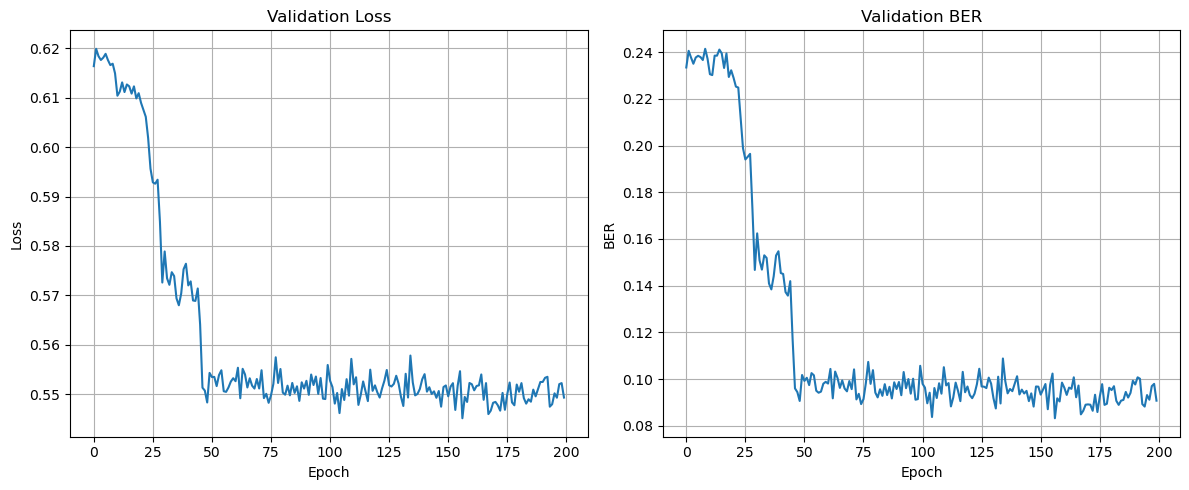

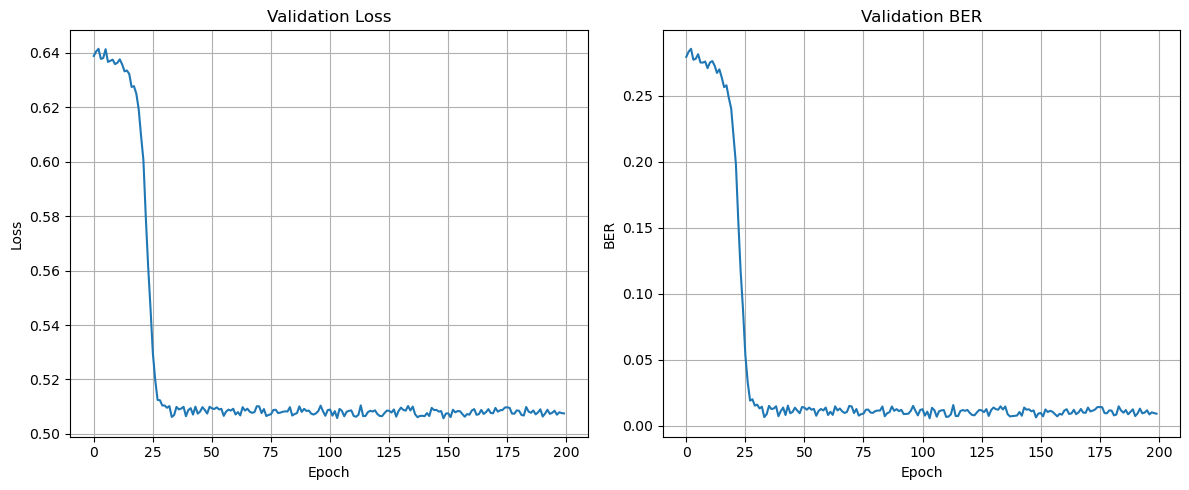

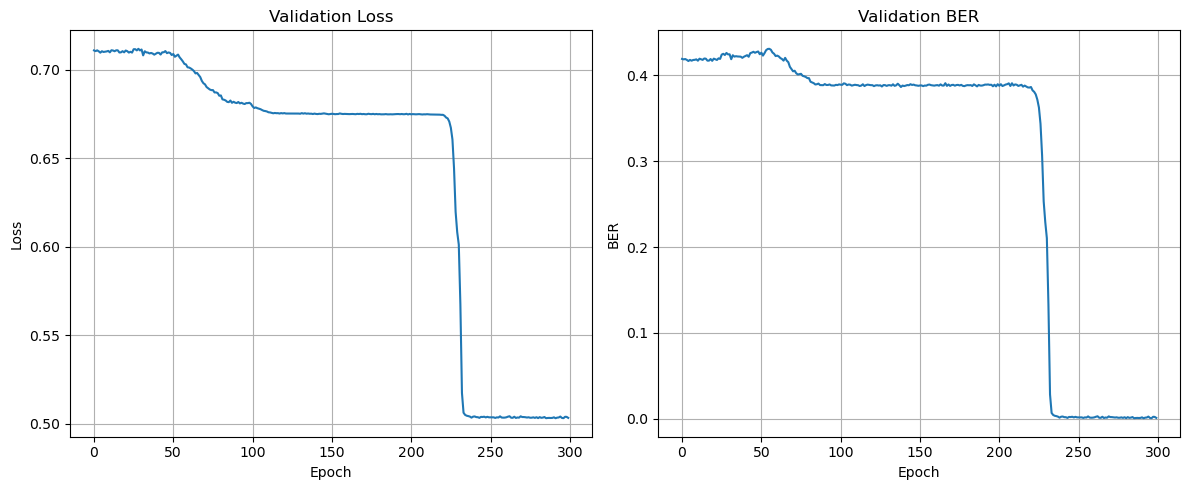

In [7]:

hierarchical_training()

In [8]:
def evaluate_ko_performance(r, m, model_path, snr_range=None, test_batch_size=1000, num_examples=10000):
    """
    Evaluate KO code performance over a range of SNRs - simplified version
    
    Args:
        r, m: KO(m,r) code parameters
        model_path: Path to the folder containing trained model weights
        snr_range: List of SNR values to test
        test_batch_size: Batch size for testing
        num_examples: Total number of examples per SNR
        
    Returns:
        bers, blers: Lists of BER and BLER values for each SNR
    """
    print(f"Evaluating KO({m},{r}) performance...")
    
    if snr_range is None:
        snr_range = np.linspace(-2, 3, 6)
    
    # Load matrices for decoding
    Mul_Ind_Zero_dict, Mul_Ind_One_dict = first_order_Mul_matrices(device, m+1)
    
    # Code dimension
    code_dim_k = sum(math.comb(m, i) for i in range(r+1))
    print(f"Code parameters: k={code_dim_k}, n={2**m}")
    
    # Create model dictionaries
    gnet_dict = {}
    fnet_dict = {}
    
    # Get the hidden size used for training by peeking at the model file
    try:
        # Try to load one of the model files to determine hidden size
        encoder_state = torch.load(f'{model_path}/Models/best_Encoder_NN.pt')
        # Get any key to check the size
        any_key = next(iter(encoder_state.keys()))
        # Get fc1.weight to check its shape
        if 'fc1.weight' in encoder_state[any_key]:
            hidden_size = encoder_state[any_key]['fc1.weight'].shape[0]
            print(f"Detected hidden size: {hidden_size}")
        else:
            # Default to 120 if we can't determine
            hidden_size = 120
            print(f"Using default hidden size: {hidden_size}")
    except Exception as e:
        # If we can't load the file, default to 120 which is what was used in training
        hidden_size = 120
        print(f"Using default hidden size: {hidden_size} (Error loading model to detect: {str(e)})")
    
    # Initialize networks with the correct hidden size and no dropout for evaluation
    for i in range(3, m+1):
        gnet_dict[i] = g_Full(2, hidden_size, 1, dropout_rate=0).to(device)
        
    for i in range(1, 2*m-3):
        fnet_dict[i] = f_Full(2 if i % 2 == 1 else 4, hidden_size, 1, dropout_rate=0).to(device)
    
    # Load best model weights
    load_model_state(gnet_dict, fnet_dict, model_path, prefix='best_', m_max=m)
    
    # Set all models to evaluation mode
    for i in range(3, m+1):
        if i in gnet_dict:
            gnet_dict[i].eval()
            
    for i in range(1, 2*m-3):
        if i in fnet_dict:
            fnet_dict[i].eval()
    
    # Storage for results
    bers = []
    blers = []
    
    # Test at each SNR
    for snr in snr_range:
        print(f"Testing at SNR = {snr:.2f} dB")
        
        total_bit_errors = 0
        total_block_errors = 0
        
        num_batches = num_examples // test_batch_size
        
        # Process batches
        for batch in range(num_batches):
           
            # Generate random message bits
            msg_bits = 2*torch.randint(0, 2, (test_batch_size, code_dim_k), 
                                      dtype=torch.float32).to(device)-1
            
            with torch.no_grad():
                # Encode
                transmit_codewords = rm_encoder_plotkin_neural(msg_bits, r, m, gnet_dict)
                
                # Add noise
                noise_sigma = snr_db2sigma(snr)
                standard_gaussian = torch.randn_like(transmit_codewords)
                corrupted_codewords = transmit_codewords + noise_sigma * standard_gaussian
                llrs = (2/(noise_sigma**2)) * corrupted_codewords
                
                # Decode
                decoded_message = rm_decoder_dumer_neural(llrs, r, m, fnet_dict, gnet_dict, 
                                                        Mul_Ind_Zero_dict, Mul_Ind_One_dict)
                
                # Calculate errors
                bit_errors = torch.sum(msg_bits != decoded_message.sign()).item()
                block_errors = torch.sum(torch.any(msg_bits != decoded_message.sign(), dim=1)).item()
                
                total_bit_errors += bit_errors
                total_block_errors += block_errors
        
        # Calculate error rates
        ber = total_bit_errors / (num_examples * code_dim_k)
        bler = total_block_errors / num_examples
        
        print(f"SNR: {snr:.2f} dB, BER: {ber:.6f}, BLER: {bler:.6f}")
        
        bers.append(ber)
        blers.append(bler)
    
    # Print table of results
    print("\nSummary of KO code performance:")
    print("==============================")
    print(f"{'SNR (dB)':<10}{'BER':<15}{'BLER':<15}")
    print("------------------------------")
    for snr, ber, bler in zip(snr_range, bers, blers):
        print(f"{snr:<10.2f}{ber:<15.6f}{bler:<15.6f}")
    
    # Plot results
    plt.figure(figsize=(10, 6))
    plt.semilogy(snr_range, bers, 'bo-', linewidth=2, label='BER')
    plt.semilogy(snr_range, blers, 'ro-', linewidth=2, label='BLER')
    plt.grid(True)
    plt.xlabel('SNR (dB)')
    plt.ylabel('Error Rate')
    plt.title(f'KO({m},{r}) Performance')
    plt.legend()
    
    # Create directory to save results if it doesn't exist
    save_dir = os.path.join(model_path, 'evaluation')
    os.makedirs(save_dir, exist_ok=True)
    
    # Save plot
    plt.savefig(os.path.join(save_dir, f'ko_{m}_{r}_performance.png'))
    
    # Also save raw results
    results = {
        'snr_range': snr_range,
        'bers': bers,
        'blers': blers,
    }
    
    # Save to file
    with open(os.path.join(save_dir, f'ko_{m}_{r}_performance.pkl'), 'wb') as f:
        pickle.dump(results, f)
    
    print(f"\nPerformance plot and data saved to {save_dir}")
    
    return bers, blers



Evaluating KO(9,4) performance...
Code parameters: k=256, n=512
Detected hidden size: 120
Successfully loaded encoder g3
Successfully loaded encoder g4
Successfully loaded encoder g5
Successfully loaded encoder g6
Successfully loaded encoder g7
Successfully loaded encoder g8
Successfully loaded encoder g9
Successfully loaded decoder f1
Successfully loaded decoder f2
Successfully loaded decoder f3
Successfully loaded decoder f4
Successfully loaded decoder f5
Successfully loaded decoder f6
Successfully loaded decoder f7
Successfully loaded decoder f8
Successfully loaded decoder f9
Successfully loaded decoder f10
Successfully loaded decoder f11
Successfully loaded decoder f12
Successfully loaded decoder f13
Successfully loaded decoder f14
Testing at SNR = -5.00 dB
SNR: -5.00 dB, BER: 0.481382, BLER: 1.000000
Testing at SNR = -4.00 dB
SNR: -4.00 dB, BER: 0.474012, BLER: 1.000000
Testing at SNR = -3.00 dB
SNR: -3.00 dB, BER: 0.462417, BLER: 0.999997
Testing at SNR = -2.00 dB
SNR: -2.00 dB, 

([0.48138213671875,
  0.47401200390625,
  0.4624172265625,
  0.43946337109375,
  0.359868484375,
  0.15028089453125,
  0.013597578125,
  0.000127921875,
  0.0,
  0.0],
 [1.0, 1.0, 0.999997, 0.998646, 0.9374, 0.52008, 0.070819, 0.001085, 0.0, 0.0])

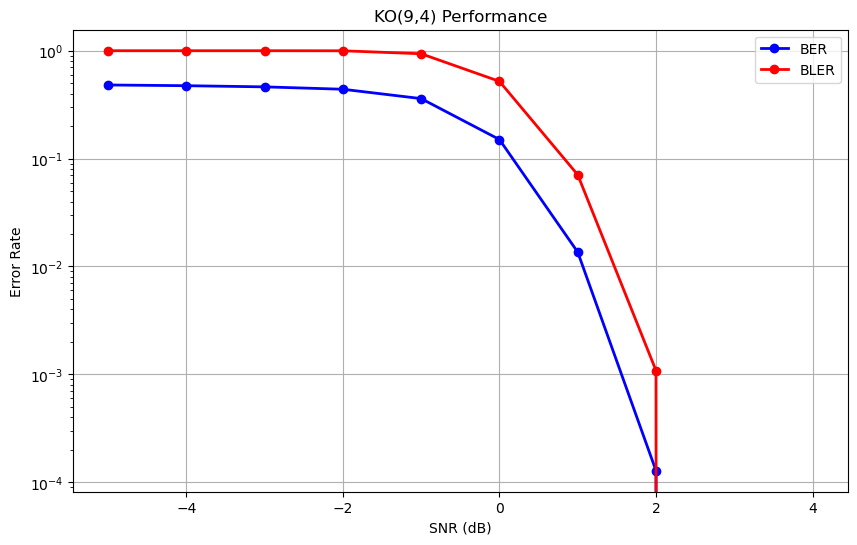

In [9]:
evaluate_ko_performance(
        r=4,  # KO(9,4)
        m=9,
        model_path='./Results/KO(9,4)_hierarchical_improved3',
        snr_range=np.linspace(-5, 4, 10),  # Adjusted SNR range for higher rate code
        test_batch_size=500,
        num_examples=10**6
    )

In [10]:
def plot_pairwise_distances(r, m, model_path, num_codewords=1000):
    """
    Plot the pairwise distance distribution for KO code vs RM code vs Gaussian codebook
    
    Args:
        r, m: KO(m,r) code parameters
        model_path: Path to the folder containing trained model weights
        num_codewords: Number of codewords to generate for the distance analysis
    """
    print(f"Analyzing pairwise distances for KO({m},{r})...")
    
    # Load matrices for decoding
    Mul_Ind_Zero_dict, Mul_Ind_One_dict = first_order_Mul_matrices(device, m+1)
    
    # Code dimension
    code_dim_k = sum(math.comb(m, i) for i in range(r+1))
    n = 2**m  # Block length
    print(f"Code parameters: k={code_dim_k}, n={n}")
    
    # Create model dictionaries
    gnet_dict = {}
    fnet_dict = {}
    
    # Get hidden size from saved model
    try:
        encoder_state = torch.load(f'{model_path}/Models/best_Encoder_NN.pt')
        any_key = next(iter(encoder_state.keys()))
        if 'fc1.weight' in encoder_state[any_key]:
            hidden_size = encoder_state[any_key]['fc1.weight'].shape[0]
        else:
            hidden_size = 120
    except Exception as e:
        hidden_size = 120
        print(f"Using default hidden size: {hidden_size}")
    
    # Initialize networks
    for i in range(3, m+1):
        gnet_dict[i] = g_Full(2, hidden_size, 1, dropout_rate=0).to(device)
        
    for i in range(1, 2*m-3):
        fnet_dict[i] = f_Full(2 if i % 2 == 1 else 4, hidden_size, 1, dropout_rate=0).to(device)
    
    # Load best model weights
    load_model_state(gnet_dict, fnet_dict, model_path, prefix='best_', m_max=m)
    
    # Set models to evaluation mode
    for i in range(3, m+1):
        if i in gnet_dict:
            gnet_dict[i].eval()
    
    # Generate random message bits for testing
    all_msg_bits = 2 * (torch.rand(num_codewords, code_dim_k) < 0.5).float() - 1
    all_msg_bits = all_msg_bits.to(device)
    
    # Generate codewords for KO code, RM code, and random Gaussian
    with torch.no_grad():
        # KO code
        codebook_ko = rm_encoder_plotkin_neural(all_msg_bits, r, m, gnet_dict)
        
        # RM code
        codebook_rm = rm_encoder_plotkin(all_msg_bits, r, m)
        
        # KO code binarized (quantized to +/-1)
        codebook_ko_quantized = codebook_ko.sign()
        
        # Random Gaussian codebook with same power constraint
        Gaussian_codebook = F.normalize(torch.randn(num_codewords, n), p=2, dim=1) * np.sqrt(n)
    
    # Calculate pairwise distances
    def pairwise_distances(codebook):
        dists = []
        for row1, row2 in combinations(codebook.cpu(), 2): 
            distance = (row1-row2).pow(2).sum()
            dists.append(np.sqrt(distance.item()))
        return dists, np.min(dists)
    
    # Get distances for each codebook
    pairwise_dist_ko, d_min_ko = pairwise_distances(codebook_ko)
    pairwise_dist_ko_quantized, d_min_ko_quantized = pairwise_distances(codebook_ko_quantized)
    pairwise_dist_rm, d_min_rm = pairwise_distances(codebook_rm)
    pairwise_dist_Gaussian, d_min_Gaussian = pairwise_distances(Gaussian_codebook)
    
    total_pairwise_dist = len(pairwise_dist_ko)
    
    # Get min/max for consistent binning
    min_dist = min(np.min(pairwise_dist_ko), np.min(pairwise_dist_rm), np.min(pairwise_dist_Gaussian))
    max_dist = max(np.max(pairwise_dist_ko), np.max(pairwise_dist_rm), np.max(pairwise_dist_Gaussian))
    
    # Create histogram bins
    bins = np.linspace(min_dist, max_dist, 1000)
    
    # Calculate histograms
    n_ko, bins_ko = np.histogram(pairwise_dist_ko, bins=bins, density=True)
    n_ko_quantized, bins_ko_quantized = np.histogram(pairwise_dist_ko_quantized, bins=bins, density=False)
    n_rm, bins_rm = np.histogram(pairwise_dist_rm, bins=bins, density=False)
    n_Gaussian, bins_Gaussian = np.histogram(pairwise_dist_Gaussian, bins=bins, density=True)
    
    # Normalize count histograms
    n_rm = (1/total_pairwise_dist) * n_rm
    n_ko_quantized = (1/total_pairwise_dist) * n_ko_quantized
    
    # Create plot with more space at the bottom for the legend
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Plot the histograms
    rm_line, = plt.plot(bins_rm[:-1], n_rm, 
            label=f'RM({m},{r}): Min dist = {d_min_rm:.2f}', 
            linewidth=2.0)
    
    ko_line, = plt.plot(bins_ko[:-1], n_ko, 
            label=f'Hi-KO({m},{r}): Min dist = {d_min_ko:.2f}', 
            linewidth=2.0)
    
    ko_q_line, = plt.plot(bins_ko_quantized[:-1], n_ko_quantized, 
            label=f'Hi-KO({m},{r}) quantized: Min dist = {d_min_ko_quantized:.2f}', 
            linewidth=2.0)
    
    gauss_line, = plt.plot(bins_Gaussian[:-1], n_Gaussian, 
            label=f'Random Gaussian: Min dist = {d_min_Gaussian:.2f}', 
            linewidth=2.0)
    
    # Customize plot
    plt.xlabel("Pairwise distances", fontsize=16)
    plt.ylabel("Probability density", fontsize=16)
    plt.title(f"Hierarchical KO({m},{r})", fontsize=16)
    
    # Add major and minor grid lines
    plt.grid(True, which='both', linestyle='-', alpha=0.7)
    plt.minorticks_on()
    plt.grid(True, which='minor', linestyle=':', alpha=0.4)
    
    # Position the legend below the x-axis label
    plt.legend(
        handles=[rm_line, ko_line, ko_q_line, gauss_line],
        loc='upper center', 
        bbox_to_anchor=(0.5, -0.1),
        ncol=2,  # Display in 2 columns
        fontsize=16,
        frameon=True,
        fancybox=True,
        shadow=True
    )
    
    # Adjust layout to make room for the legend
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.2)  # Add extra space at the bottom
    
    # Save plot
    os.makedirs(os.path.join(model_path, 'analysis'), exist_ok=True)
    plt.savefig(os.path.join(model_path, 'analysis', f'pairwise_distances_KO({m},{r}).pdf'), format='pdf', bbox_inches='tight')
    plt.savefig(os.path.join(model_path, 'analysis', f'pairwise_distances_KO({m},{r}).png'), format='png', bbox_inches='tight')
    
    print(f"Pairwise distance plot saved to {os.path.join(model_path, 'analysis')}")
    
    # Save the histogram data
    np.savez(os.path.join(model_path, 'analysis', f'pairwise_distances_data_KO({m},{r}).npz'),
             ko_dist=pairwise_dist_ko,
             ko_quantized_dist=pairwise_dist_ko_quantized,
             rm_dist=pairwise_dist_rm,
             gaussian_dist=pairwise_dist_Gaussian,
             bins=bins,
             min_distances={
                 'ko': d_min_ko,
                 'ko_quantized': d_min_ko_quantized,
                 'rm': d_min_rm,
                 'gaussian': d_min_Gaussian
             })
    
    # Print minimum distances
    print(f"\nMinimum distances:")
    print(f"Hierarchical KO({m},{r}): {d_min_ko:.4f}")
    print(f"Quantized Hi-KO({m},{r}): {d_min_ko_quantized:.4f}")
    print(f"RM({m},{r}): {d_min_rm:.4f}")
    print(f"Random Gaussian: {d_min_Gaussian:.4f}")
    
    return fig



Analyzing pairwise distances for KO(9,4)...
Code parameters: k=256, n=512
Successfully loaded encoder g3
Successfully loaded encoder g4
Successfully loaded encoder g5
Successfully loaded encoder g6
Successfully loaded encoder g7
Successfully loaded encoder g8
Successfully loaded encoder g9
Successfully loaded decoder f1
Successfully loaded decoder f2
Successfully loaded decoder f3
Successfully loaded decoder f4
Successfully loaded decoder f5
Successfully loaded decoder f6
Successfully loaded decoder f7
Successfully loaded decoder f8
Successfully loaded decoder f9
Successfully loaded decoder f10
Successfully loaded decoder f11
Successfully loaded decoder f12
Successfully loaded decoder f13
Successfully loaded decoder f14
Pairwise distance plot saved to ./Results/KO(9,4)_hierarchical_improved3/analysis

Minimum distances:
Hierarchical KO(9,4): 27.9515
Quantized Hi-KO(9,4): 28.0000
RM(9,4): 28.0000
Random Gaussian: 27.5083


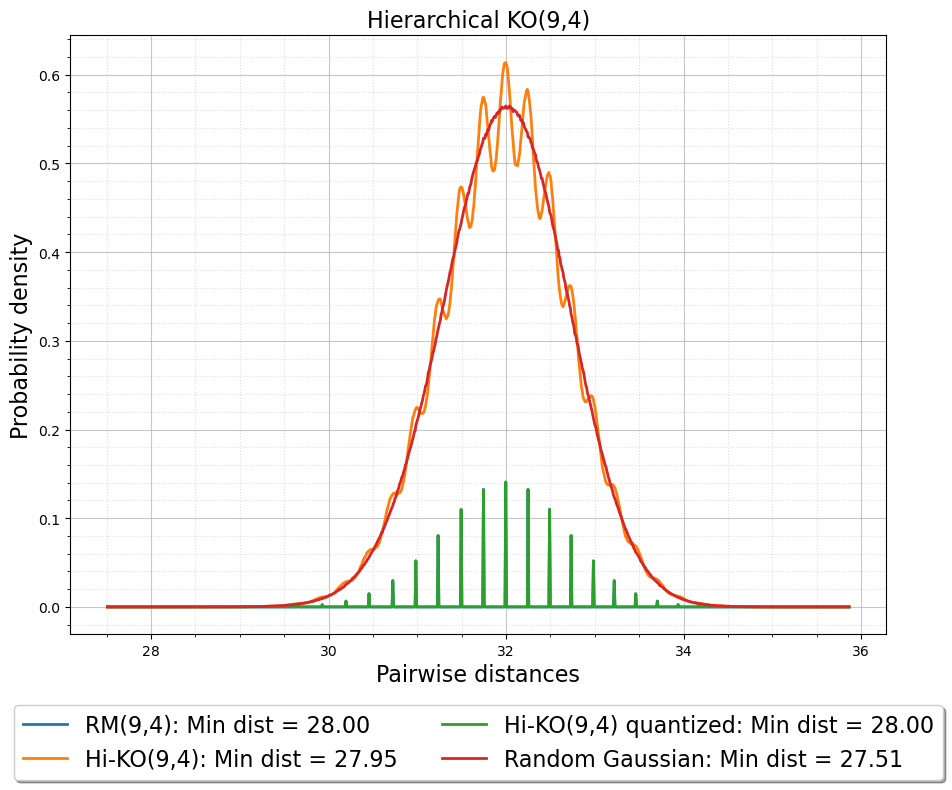

In [11]:
# Call the function to plot pairwise distances for KO(8,3)
r, m = 4, 9
model_path = './Results/KO(9,4)_hierarchical_improved3'
fig = plot_pairwise_distances(r, m, model_path, num_codewords=10000)
plt.show()  # Show the plot in interactive environments